# House Price Prediction

Goal: predict a house's sale price from its square footage, bedrooms, bathrooms, location and year built.

Data: house sales in King County (Seattle, USA), 2014–2015.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("../data/kc_house_data.csv")
print(df.shape)
df[["price", "sqft_living", "bedrooms", "bathrooms", "yr_built", "lat", "long"]].head()

(21613, 21)


,price,sqft_living,bedrooms,bathrooms,yr_built,lat,long
0,221900.0,1180,3,1.00,1955,47.5112,-122.257
1,538000.0,2570,3,2.25,1951,47.7210,-122.319
2,180000.0,770,2,1.00,1933,47.7379,-122.233
3,604000.0,1960,4,3.00,1965,47.5208,-122.393
4,510000.0,1680,3,2.00,1987,47.6168,-122.045


## 1. Exploring the data

In [2]:
df[["price", "sqft_living", "bedrooms", "bathrooms", "yr_built"]].describe().round(1)

,price,sqft_living,bedrooms,bathrooms,yr_built
count,21613.0,21613.0,21613.0,21613.0,21613.0
mean,540088.1,2079.9,3.4,2.1,1971.0
std,367127.2,918.4,0.9,0.8,29.4
min,75000.0,290.0,0.0,0.0,1900.0
25%,321950.0,1427.0,3.0,1.8,1951.0
50%,450000.0,1910.0,3.0,2.2,1975.0
75%,645000.0,2550.0,4.0,2.5,1997.0
max,7700000.0,13540.0,33.0,8.0,2015.0


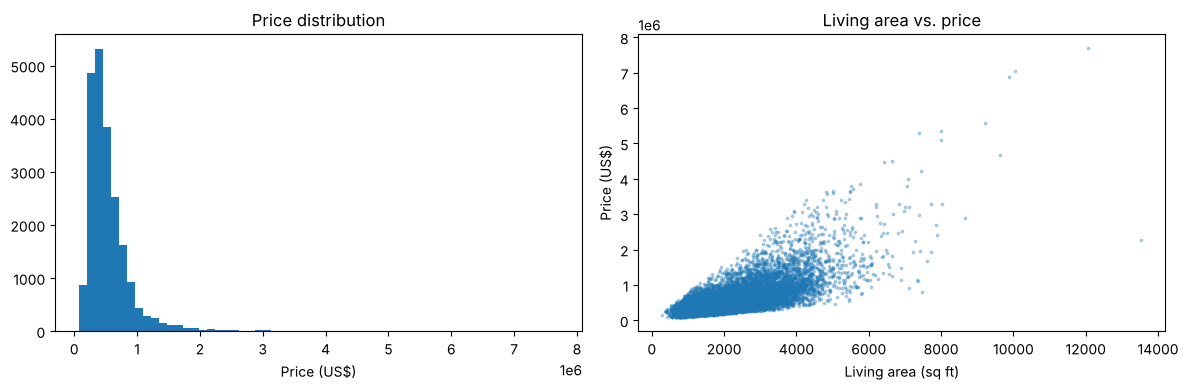

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["price"], bins=60)
axes[0].set_title("Price distribution")
axes[0].set_xlabel("Price (US$)")
axes[1].scatter(df["sqft_living"], df["price"], s=3, alpha=0.3)
axes[1].set_title("Living area vs. price")
axes[1].set_xlabel("Living area (sq ft)")
axes[1].set_ylabel("Price (US$)")
plt.tight_layout()
plt.savefig("../images/exploration.png", dpi=100)
plt.show()

## 2. Preparing the data

We use the project features: square footage, bedrooms, bathrooms, location (latitude/longitude) and year built.

In [4]:
features = ["sqft_living", "bedrooms", "bathrooms", "lat", "long", "yr_built"]
X = df[features]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (17290, 6)  Test: (4323, 6)


## 3. Training the models

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Mean absolute error (US$)": round(mean_absolute_error(y_test, pred)),
        "R²": round(r2_score(y_test, pred), 3),
    })

pd.DataFrame(results)

,Model,Mean absolute error (US$),R²
0,Linear Regression,148898,0.599
1,Decision Tree,108837,0.688


## 4. What drives the price?

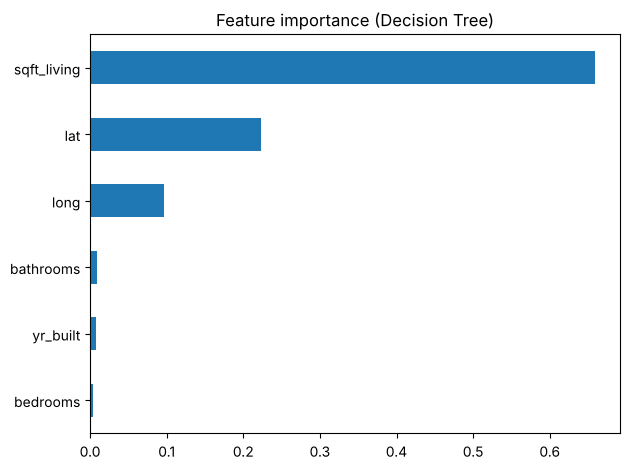

In [6]:
tree = models["Decision Tree"]
importance = pd.Series(tree.feature_importances_, index=features).sort_values()
importance.plot.barh(title="Feature importance (Decision Tree)")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=100)
plt.show()

## 5. Conclusions

- Living area and location explain most of the price.
- The Decision Tree captures the effect of location better than Linear Regression, which assumes straight-line relationships.
- Next steps: try a Random Forest, handle price outliers and use `zipcode` as a feature.